# Project 01: Exploratory Data Analysis (EDA) on Titanic
**Track:** Data Science & AI  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Objective
Clean and explore the Titanic passenger dataset using Pandas, then use grouped statistics to investigate survival patterns. This notebook follows the supplied learner guide.

## Questions
1. Did survival rates differ between female and male passengers?
2. Did passenger class relate to survival rate?
3. How did survival rates vary across age bands?

> **Important:** These are descriptive comparisons. They show associations in this dataset, not proof that a characteristic caused survival.


## 1. Import libraries and load the dataset
The Seaborn Titanic dataset is loaded in one line. The first run may need an internet connection to download the dataset.

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = sns.load_dataset("titanic")
print("Dataset loaded successfully.")

Dataset loaded successfully.


## 2. Inspect the data
Use `shape`, `head()`, `info()`, and `describe()` to understand the size, columns, data types, and numeric distributions.

In [68]:
print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [70]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Column notes
- `survived`: 1 = survived, 0 = did not survive
- `pclass`: passenger ticket class (1, 2, or 3)
- `sex`: recorded passenger sex category
- `age`: passenger age in years
- `embarked`: embarkation port category
- `deck`: recorded cabin deck category

Other columns describe factors such as fare, family aboard, embarkation, and travel class. `describe()` summarizes numeric and categorical columns differently.


## 3. Write down the missing-value profile
Count missing values before making any cleaning decisions.

In [71]:
missing_before = df.isna().sum().sort_values(ascending=False)
display(missing_before[missing_before > 0].to_frame("missing_count"))
print("Total missing cells:", int(df.isna().sum().sum()))

,missing_count
deck,688
age,177
embarked,2
embark_town,2


Total missing cells: 869


## 4. Clean missing values with reasons
- **Age:** fill missing ages using the median for the same passenger class and sex. This uses more specific groups than a single overall median.
- **Embarked:** fill missing values with the mode (most frequent category).
- **Deck:** drop this column because it has substantial missingness, as directed by the learner guide.
- **Duplicates:** count duplicate rows and report the count. Do not automatically remove them: identical-looking records are not necessarily confirmed duplicate passengers, and the guide asks us to count them.


In [72]:
df_clean = df.copy()

# Fill age using median age for each passenger class and sex.
age_group_medians = df_clean.groupby(["pclass", "sex"])["age"].transform("median")
df_clean["age"] = df_clean["age"].fillna(age_group_medians)

# Defensive fallback in case any age values remain missing in an unusual dataset version.
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())

# Fill missing embarkation ports with the most frequent value.
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])

# Drop deck because it is mostly empty.
if "deck" in df_clean.columns:
    df_clean = df_clean.drop(columns=["deck"])

duplicate_count = int(df_clean.duplicated().sum())
print("Duplicate rows found:", duplicate_count)
print("Missing values after cleaning:")
display(df_clean.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Duplicate rows found: 118
Missing values after cleaning:


,missing_count
embark_town,2
survived,0
sex,0
age,0
sibsp,0
pclass,0
parch,0
fare,0
class,0
embarked,0


## 5. Check data types
Review the data types and convert selected categorical columns to the category type where appropriate.

In [73]:
categorical_columns = [
    col for col in ["survived", "pclass", "sex", "embarked", "who",
                    "adult_male", "alone", "class", "embark_town"]
    if col in df_clean.columns
]

for col in categorical_columns:
    df_clean[col] = df_clean[col].astype("category")

display(df_clean.dtypes.to_frame("data_type"))

,data_type
survived,category
pclass,category
sex,category
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,category
class,category
who,category


## 6. Compare survival by sex
The survival rate is the mean of the `survived` indicator (where 1 means survived).

In [74]:

# Compare survival rates by sex
survival_by_sex = (
    df_clean.assign(survived=df_clean["survived"].astype(int))
    .groupby("sex", observed=True)["survived"]
    .agg(survival_rate="mean", passenger_count="count")
    .sort_values("survival_rate", ascending=False)
)

survival_by_sex["survival_percent"] = survival_by_sex["survival_rate"] * 100

display(survival_by_sex.round(2))



,survival_rate,passenger_count,survival_percent
sex,,,
female,0.74,314,74.20
male,0.19,577,18.89


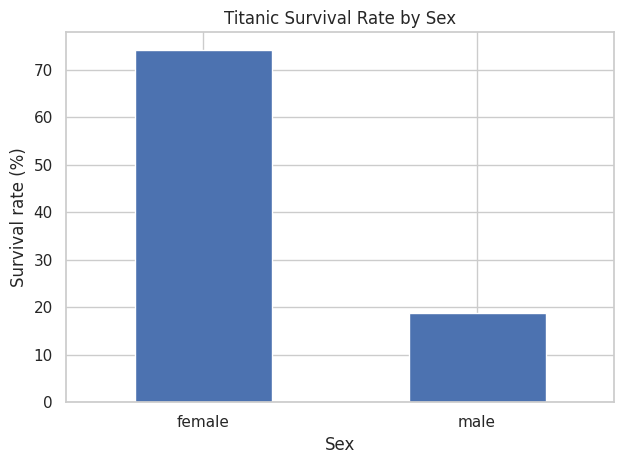

In [75]:
ax = (survival_by_sex["survival_rate"] * 100).plot(kind="bar", rot=0)
ax.set_title("Titanic Survival Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Survival rate (%)")
plt.tight_layout()
plt.show()

## 7. Compare survival by passenger class

In [76]:
# Step 1: Create age groups
age_bins = [0, 12, 18, 40, 60, 100]
age_labels = ["Child", "Teen", "Adult", "Middle-aged", "Senior"]

df_clean["age_band"] = pd.cut(
    df_clean["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Step 2: Calculate survival rates
survival_by_age_band = (
    df_clean
    .assign(survived=df_clean["survived"].astype(int))
    .groupby("age_band", observed=True)["survived"]
    .agg(
        survival_rate="mean",
        passenger_count="count"
    )
)

# Step 3: Convert rates to percentages
survival_by_age_band["survival_percent"] = (
    survival_by_age_band["survival_rate"] * 100
)

# Step 4: Display results
display(survival_by_age_band.round(2))


,survival_rate,passenger_count,survival_percent
age_band,,,
Child,0.58,69,57.97
Teen,0.43,70,42.86
Adult,0.36,602,36.05
Middle-aged,0.39,128,39.06
Senior,0.23,22,22.73


,survival_rate,passenger_count,survival_percent
pclass,,,
1,0.63,216,62.96
2,0.47,184,47.28
3,0.24,491,24.24


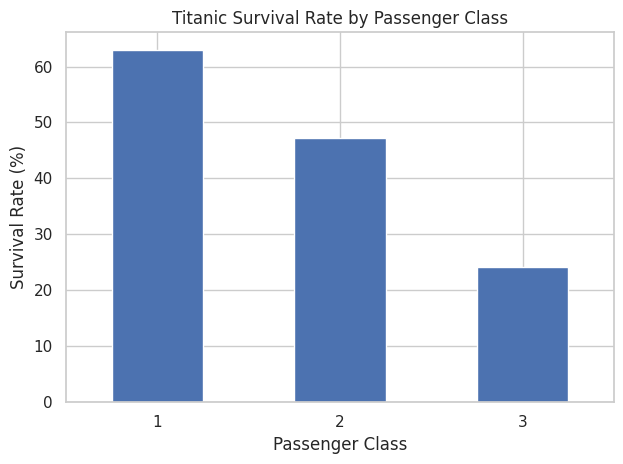

In [77]:
# Fix survival column data type
df_clean["survived"] = df_clean["survived"].astype(int)

# Calculate survival rates by passenger class
survival_by_class = (
    df_clean.groupby("pclass", observed=True)
    .agg(
        survival_rate=("survived", "mean"),
        passenger_count=("survived", "count")
    )
    .sort_values("survival_rate", ascending=False)
)

# Calculate survival percentage
survival_by_class["survival_percent"] = (
    survival_by_class["survival_rate"] * 100
)

# Display results
display(survival_by_class.round(2))

# Visualize results
ax = survival_by_class["survival_percent"].plot(
    kind="bar",
    rot=0
)

ax.set_title("Titanic Survival Rate by Passenger Class")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Survival Rate (%)")

plt.tight_layout()
plt.show()

## 8. Compare survival by age band
Create age bands with `pd.cut()` and compare their survival rates.

In [78]:
age_bins = [0, 12, 18, 40, 60, 100]
age_labels = ["Child", "Teen", "Adult", "Middle-aged", "Senior"]

df_clean["age_band"] = pd.cut(
    df_clean["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True,
    right=True
)

survival_by_age_band = (
    df_clean.groupby("age_band", observed=True)["survived"]
    .agg(survival_rate="mean", passenger_count="count")
)
survival_by_age_band["survival_percent"] = survival_by_age_band["survival_rate"] * 100
display(survival_by_age_band.round(2))

,survival_rate,passenger_count,survival_percent
age_band,,,
Child,0.58,69,57.97
Teen,0.43,70,42.86
Adult,0.36,602,36.05
Middle-aged,0.39,128,39.06
Senior,0.23,22,22.73


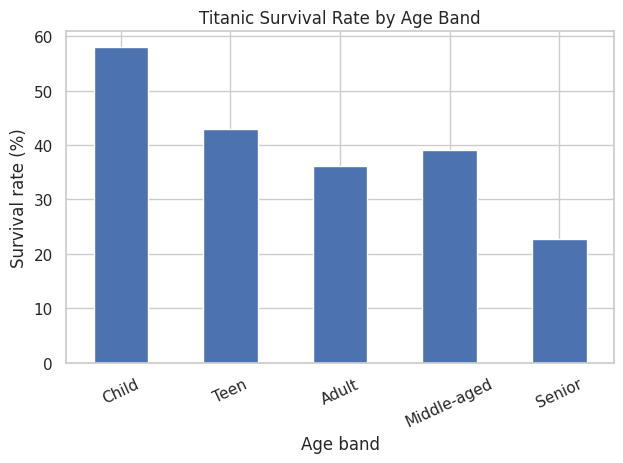

In [79]:
ax = (survival_by_age_band["survival_rate"] * 100).plot(kind="bar", rot=25)
ax.set_title("Titanic Survival Rate by Age Band")
ax.set_xlabel("Age band")
ax.set_ylabel("Survival rate (%)")
plt.tight_layout()
plt.show()

## 9. Answer the three questions with real numbers
The following cell generates concise findings directly from the dataset so the summary is based on the notebook's actual output, rather than guessed numbers.

In [80]:
# Q1: sex comparison
sex_rates = (df_clean.groupby("sex", observed=True)["survived"].mean() * 100)
if "female" in sex_rates.index and "male" in sex_rates.index:
    print(
        f"1. Sex: female passengers had a survival rate of {sex_rates['female']:.1f}%, "
        f"compared with {sex_rates['male']:.1f}% for male passengers."
    )
else:
    print("1. Sex: inspect the table above; expected female and male categories were not both present.")

# Q2: class comparison
class_rates = (df_clean.groupby("pclass", observed=True)["survived"].mean() * 100).sort_index()
if len(class_rates) >= 2:
    print(
        "2. Passenger class: survival rates by class were "
        + ", ".join([f"class {int(k)}: {v:.1f}%" for k, v in class_rates.items()])
        + "."
    )

# Q3: age-band comparison
age_rates = (df_clean.groupby("age_band", observed=True)["survived"].mean() * 100).dropna()
if not age_rates.empty:
    best_band = age_rates.idxmax()
    print(
        f"3. Age band: {best_band} passengers had the highest observed survival rate "
        f"among the age bands with data ({age_rates.max():.1f}%)."
    )

1. Sex: female passengers had a survival rate of 74.2%, compared with 18.9% for male passengers.
2. Passenger class: survival rates by class were class 1: 63.0%, class 2: 47.3%, class 3: 24.2%.
3. Age band: Child passengers had the highest observed survival rate among the age bands with data (58.0%).


## 10. Conclusion
After running the notebook, use the three generated findings above to write a short summary in your own words. Mention the percentages and avoid claiming causation.

## 11. Final submission checklist
- [ ] Three questions are written at the start.
- [ ] `shape`, `head()`, `info()`, and `describe()` are included.
- [ ] Missing values are counted and cleaning choices are explained.
- [ ] Duplicate rows are counted.
- [ ] Survival rates are compared by sex, passenger class, and age band.
- [ ] Each question has a sentence containing a real number.
- [ ] Restart the kernel and run all cells from top to bottom.
- [ ] Export to HTML or PDF if required and submit the notebook link with sharing enabled.

**Reproducibility note:** Results depend on the dataset version. Do not copy example percentages without checking your own output.
